# 05-中断与定时器

> 让 CPU 在“事件发生时”执行短处理，让硬件定时器按明确的时钟、分频和重装载值产生节拍。

这是「嵌入式单片机一套通关」十二篇笔记的第 05 篇，承接第 04 篇的 GPIO、按键、蜂鸣器和 SysTick 预备知识。本篇把轮询程序升级为**中断响应**，再用 SysTick、基本定时器和 PWM 处理稳定时序。

学完应能回答四个问题：事件从哪里来？它怎样进入 ISR？中断里应该做多少工作？定时器的 `CK_TIMER`、`PSC`、`CAR` 如何共同决定周期？


## 1. 本篇范围与资料说明

| 课程小节 | 本篇整理重点 |
|---|---|
| 中断基础概念 | 主逻辑、ISR、内部/外部中断、NVIC 优先级 |
| 外部中断 EXTI | 触发沿、EXTI 线映射、挂起标志、按键案例 |
| 按键切换音乐播放器 | ISR 写状态，主循环切换歌曲，避免在 ISR 播放 |
| 定时器概述与查询表 | SysTick、基本/通用/高级定时器的能力边界 |
| 时钟周期、分频器、晶振与 PLL | 时钟来源、分频和计数周期的关系 |
| SysTick 内核定时器 | 1 ms 节拍、延时依赖链与高频中断代价 |
| 基本定时器 | TIMER5/6、更新中断、16 位 PSC/CAR 计算 |
| 配套手册 | EXTI、NVIC、TIMER 时钟和寄存器语义核对 |

**来源：**[用户提供的知识库](https://www.yuque.com/embheima/mcu)，当前跳转到[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。已阅读中断、EXTI、播放器案例、定时器和超声波等课程页面，并用 [CMSIS NVIC 文档](https://arm-software.github.io/CMSIS_6/main/Core/group__NVIC__gr.html)、[CMSIS SysTick 文档](https://arm-software.github.io/CMSIS_6/main/Core/group__SysTick__gr.html)以及 [GD32F4xx User Manual](https://gd32mcu.com/download/down/document_id/98/path_type/1) 的可访问内容核对关键概念。

**整理方式：**代码、时序图、公式和练习是重写的学习补充；课程压缩包和完整工程没有下载。网页中的长代码只按可见片段核对，以下程序不能脱离对应 GD32F4xx SPL、启动文件、芯片型号和工程配置直接承诺可构建。

**示例环境：**GD32F407VET6 课程板、GD32F4xx SPL、C99/Cortex-M4/CMSIS。沿用第 04 篇的 PA0 核心按键、PB2 核心 LED 和 PB9 蜂鸣器；本次播放器页面进一步给出 PC0～PC3 四个扩展按键映射。

**阅读边界：**11 个课程页面的可访问正文、基本定时器完整短配置片段，以及官方手册 3.4 的相关页。课程 Gitee 示例链接当前出现安全验证码，未读取仓库或完成验证码；本篇没有把未读取内容当作验证依据。PWM 和非阻塞调度是针对本篇主线的补充。

本次没有编译芯片工程、烧录开发板、接示波器或测量真实中断周期；定时数值是基于明确假设的算例。


## 2. 为什么需要中断

轮询是主循环不断询问：

```c
while (1) {
    if (key_is_pressed()) {
        handle_key();
    }
    do_other_work();
}
```

它容易理解，但响应时间受循环长度影响；如果主循环正在阻塞发声、延时或处理较长数据，按键和串口事件只能等下一轮。

中断把流程改成：

```text
外部/内部事件 → 外设置位请求或挂起标志 → NVIC 判断
→ CPU 保存现场并跳到向量表中的 ISR
→ ISR 快速确认来源、清标志、记录事件
→ 异常返回，继续被打断的主逻辑
```

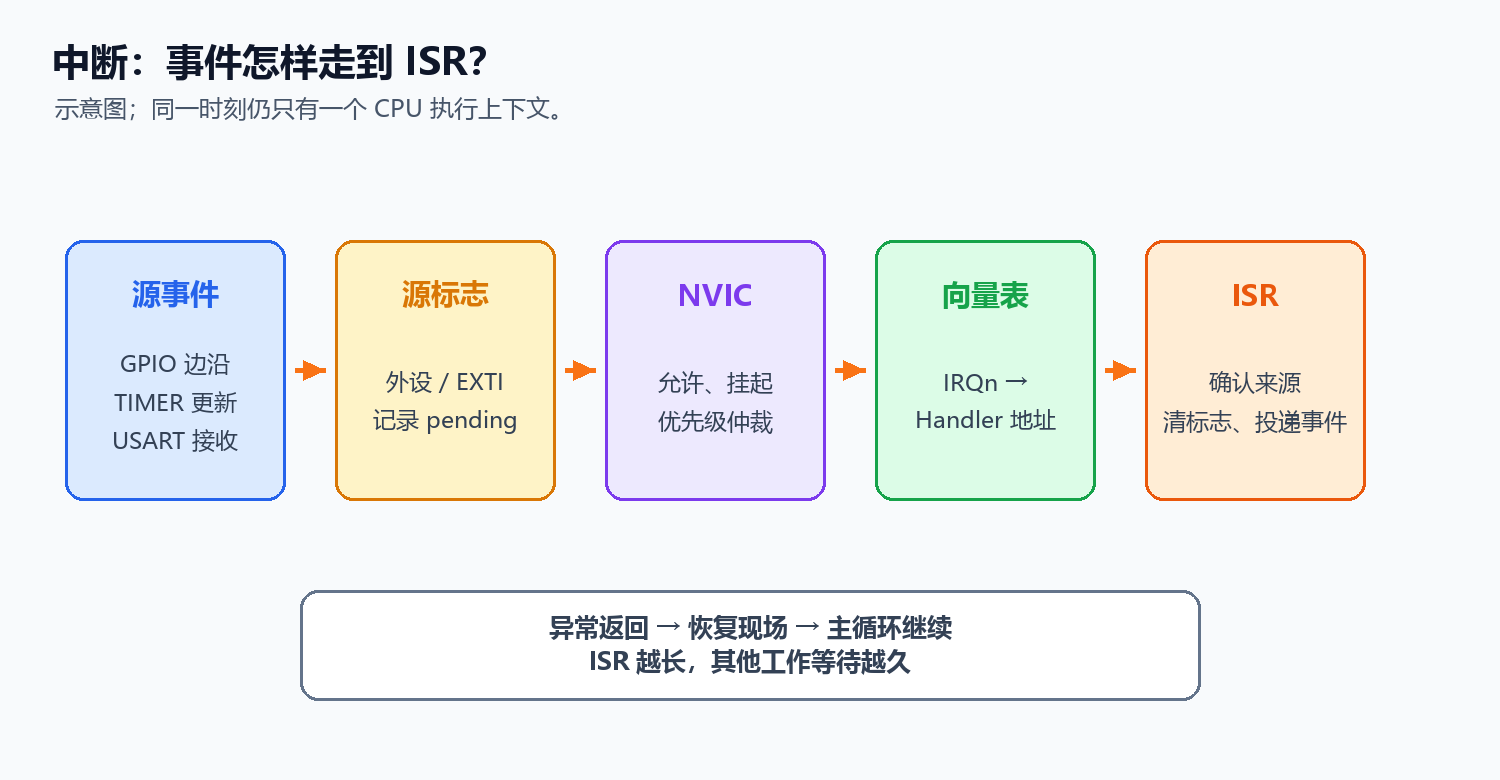

中断不是“同时执行两个 C 函数”。同一时刻仍只有一个 CPU 上下文在运行；处理器暂停主逻辑，保存必要现场，执行 ISR，再恢复现场。若 ISR 太长，主循环和其他中断都会受到影响。

适合中断的工作：记录时间、读取简短状态、置位事件标志、搬运一个字节。引入 RTOS 后还可使用对应的 ISR 专用唤醒接口。播放整首歌曲、格式化长字符串、动态内存分配和阻塞延时应放在主循环或任务中。

上述轮询代码是伪接口片段，`key_is_pressed()` 等名字用于说明职责，并非 SPL 已提供的函数。各实验的 main/Handler 是独立方案；真实工程只能保留一个同名入口，不能把所有代码块同时加入。


## 3. 内部中断、外部中断与异常

课程按请求来源把中断分为内部和外部两类。Cortex-M/CMSIS 还有另一种分类：内核异常与设备 IRQ。“外部 IRQ”相对于内核，可以来自片上 TIMER、USART，并非只指芯片外面的按键：

| 类型 | 例子 | 典型入口 |
|---|---|---|
| 内核异常 | HardFault、SysTick、PendSV | Cortex-M 向量表 |
| 外设内部请求 | TIMER 更新、USART 接收、DMA 完成 | 设备 IRQ 与 ISR |
| 外部引脚触发 | 按键、传感器边沿，经 EXTI | EXTI IRQ 与 ISR |
| 软件触发 | 写 EXTI 软件触发寄存器、设置 pending | 仍由 NVIC/向量入口处理 |

Cortex-M 向量表同时包含初始栈指针、复位入口、内核异常和设备中断入口。CMSIS 文档说明，启动文件通常先提供弱定义的默认处理函数，应用使用相同名字定义自己的处理函数即可覆盖它。

中断名字必须与目标启动文件一致。例如 GD32F4xx 的 TIMER5 全局中断在手册向量表中与 DAC 欠载错误共享 IRQ，课程示例入口为 `TIMER5_DAC_IRQHandler`；不要把它凭经验写成其他系列的名字。

中断的“请求产生”“NVIC 允许”“外设中断源允许”是不同层次。只调用 `nvic_irq_enable()`，没有打开外设内部中断位，ISR 不会按预期触发；只打开外设标志，NVIC 未开放，也不会进入 ISR。


## 4. 一次中断的四个状态

把一次事件拆成四个状态，可以避免“为什么进不了中断”的盲目排查：

1. **源事件发生：**引脚出现边沿，定时器溢出，串口收到数据。
2. **挂起标志置位：**外设或 EXTI 记录“有事情发生”。
3. **通道被允许：**外设中断使能和 NVIC IRQ 使能都有效，且没有被全局屏蔽。
4. **CPU 接管：**当前优先级条件满足，处理器进入向量表指定的 ISR。

ISR 处理一般包含：

```c
if (source_flag_is_set()) {
    clear_source_flag();
    event_flags |= EVENT_X;
}
```

清标志是“确认已经处理这次请求”。若不清，ISR 可能刚返回就再次进入；若先清再处理，新的事件可能在处理期间重新置位，具体行为要看外设标志的硬件语义。对于共享 IRQ，应逐个检查可能的来源并分别清除。

不要把一个 `volatile bool` 当成无限容量的事件队列。连续发生两次事件而主循环只来得及清一次时，后一次可能被合并；若每次都必须保留，应使用计数器或环形队列，并处理并发访问。


## 5. `volatile`、竞态与 ISR 共享数据

主循环和 ISR 共享的简单标志通常声明为 `volatile`：

```c
static volatile bool key_event_pending;
static volatile uint32_t timer_ticks;
```

`volatile` 只告诉编译器每次访问都可能受外部执行流影响；它不保证复合操作原子、不提供互斥，也不自动解决“读到一半被改写”。

推荐让 ISR 做最小写入，主循环负责消费。下面把“取出并清除”放在极短临界区中；需要 `gd32f4xx.h`、`<stdbool.h>`、`<stdint.h>` 和匹配的 CMSIS：

```c
static volatile bool key_event_pending;

void EXTI0_IRQHandler(void)
{
    if (SET == exti_interrupt_flag_get(EXTI_0)) {
        exti_interrupt_flag_clear(EXTI_0);
        key_event_pending = true;
    }
}

static bool take_key_event(void)
{
    uint32_t saved_primask = __get_PRIMASK();
    __disable_irq();
    bool pending = key_event_pending;
    key_event_pending = false;
    __set_PRIMASK(saved_primask);
    return pending;
}
```

主循环调用 `take_key_event()` 后再处理业务。保存并恢复 PRIMASK，避免把调用前已经屏蔽的中断错误地重新打开。PRIMASK 屏蔽可配置异常，NMI/HardFault 不在本例保护范围内；本例假设这些异常不访问该标志。

若没有保护，ISR 可能在主循环“读到 true”和“写回 false”之间再置一次 true，新事件随即被清掉。本方法解决这段交换的竞态，**仍只保存“至少一次事件”**，两个尚未消费的边沿会合并。必须逐次保存时改用有容量与溢出策略的队列/计数。

对齐的 32 位对象在该 Cortex-M4 和匹配工具链下可用单次加载取得快照；`counter++` 仍是读取、运算、写回的复合操作。若多个上下文都写同一计数，需额外同步。后文的毫秒计数只有 TIMER5 ISR 写、主循环只读，不在主循环清零。

如果需要传递多个字段（例如事件类型和时间戳），先设计一致性策略：短临界区、带有正确发布顺序的队列，或使用 RTOS 同步原语。不要因为变量加了 `volatile` 就认为结构体复制和多字节计数一定安全。


## 6. NVIC 优先级：抢占与响应顺序

NVIC 负责嵌套、屏蔽、挂起和优先级。GD32F407VET6 的手册写明使用 4 个优先级位，共 16 个优先级编码；优先级分组决定这些位如何分给抢占优先级和子优先级。

| 概念 | 作用 |
|---|---|
| 抢占优先级 | 当前 ISR 执行时，另一个中断能否打断它 |
| 子优先级 | 抢占优先级相同且同时 pending 时，决定先服务谁 |
| pending | 请求已经发生，但还没开始或正在等待 |
| active | ISR 已开始但尚未异常返回；被更高优先级抢占后仍可处于 active |
| priority grouping | 把实现的优先级位切成抢占部分和子优先级部分 |

数值越小通常表示优先级越高，但要区分库函数参数、编码后的寄存器值和芯片实现的有效位。CMSIS 的 `NVIC_SetPriority()` 也明确说明较小值代表更高优先级。

课程示例的 `nvic_irq_enable(EXTI0_IRQn, 1, 1)` 或 `nvic_irq_enable(TIMER5_DAC_IRQn, 2, 2)` 是 SPL 风格的配置。它们只有在当前芯片头文件、优先级分组和函数签名匹配时才有意义。

一个常见误解是“子优先级等待越久会自动升高”。NVIC 不会因为等待时间增加而动态改变优先级；如果需要防止低优先级事件长期得不到服务，应缩短高优先级 ISR、控制事件频率或设计队列与调度策略。

### 4 位优先级的五种常用分组

| SPL 分组 | 抢占位数/范围 | 子优先级位数/范围 |
|---|---|---|
| `NVIC_PRIGROUP_PRE0_SUB4` | 0 位，只能填 0 | 4 位，0～15 |
| `NVIC_PRIGROUP_PRE1_SUB3` | 1 位，0～1 | 3 位，0～7 |
| `NVIC_PRIGROUP_PRE2_SUB2` | 2 位，0～3 | 2 位，0～3 |
| `NVIC_PRIGROUP_PRE3_SUB1` | 3 位，0～7 | 1 位，0～1 |
| `NVIC_PRIGROUP_PRE4_SUB0` | 4 位，0～15 | 0 位，只能填 0 |

```c
nvic_priority_group_set(NVIC_PRIGROUP_PRE2_SUB2);
nvic_irq_enable(EXTI0_IRQn, 1U, 1U);
nvic_irq_enable(TIMER5_DAC_IRQn, 2U, 2U);
```

在本例分组下，EXTI0 的抢占级 1 高于 TIMER5 的 2。两个 IRQ 若抢占级相同，即使子优先级不同，也不能靠子优先级互相抢占；等 CPU 可响应时再比较子优先级。若编码也相同，硬件再按异常号等规则仲裁。

分组是整个系统配置，应在初始化中统一设定，再配置各 IRQ。不要依赖某版库函数在遇到未知分组时的默认补救逻辑，也不要在一个外设驱动中随意改分组影响其他模块。


## 7. EXTI：把 GPIO 边沿送入 NVIC

GD32F4xx 手册给出 EXTI 最多 23 条独立边沿检测线路，其中 GPIO 外部线通过 SYSCFG 选择来源；每条线可选择上升沿、下降沿或双边沿，并可作为中断或事件。

按键电路的有效电平决定触发沿：

| 按键电路 | 松开 | 按下 | 适合的按下沿 |
|---|---:|---:|---|
| PA0 外部下拉接 3V3 | 0 | 1 | 上升沿 |
| PC0～PC3 内部上拉、按下接 GND | 1 | 0 | 下降沿 |
| 需要按下和释放都处理 | 由电路决定 | 由电路决定 | 双边沿 |

同一个 EXTI 线号在同一时刻只能选择一个端口来源：PA0、PB0、PC0 都可映射到 EXTI0，但不能把它们同时作为 EXTI0 的三个独立输入。不同线号可以分别映射不同端口。

GPIO 对应 EXTI0～EXTI15，共 **16 条**，并非 15 条；其余 EXTI 线连接芯片内部模块。引出哪些端口、封装是否有对应脚，另看具体芯片资料。EXTI5～9 与 EXTI10～15 分别共享 IRQ 入口，需在共享 Handler 内逐项识别来源。

### PA0 上升沿配置片段

```c
static void key_exti_init(void)
{
    // 在本独立实验开始时调用；分组已由系统统一设置
    NVIC_DisableIRQ(EXTI0_IRQn);
    rcu_periph_clock_enable(RCU_GPIOA);
    rcu_periph_clock_enable(RCU_SYSCFG);

    gpio_mode_set(GPIOA, GPIO_MODE_INPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_0);
    syscfg_exti_line_config(EXTI_SOURCE_GPIOA,
                            EXTI_SOURCE_PIN0);
    exti_init(EXTI_0, EXTI_INTERRUPT, EXTI_TRIG_RISING);
    exti_interrupt_enable(EXTI_0);
    exti_interrupt_flag_clear(EXTI_0);
    NVIC_ClearPendingIRQ(EXTI0_IRQn);
    nvic_irq_enable(EXTI0_IRQn, 1U, 1U);
}
```

这里的 PA0 依赖第 04 篇已经核对的外部下拉；若换成 PC0 内部上拉，要改为 GPIOC 时钟/端口、`GPIO_PUPD_PULLUP`、`EXTI_SOURCE_GPIOC` 和 `EXTI_TRIG_FALLING`。PA0 和 PC0 实验分别运行，不能同时占 EXTI0。

依赖 `gd32f4xx_exti.c`、`gd32f4xx_syscfg.c`、GPIO/RCU/MISC 与匹配启动文件。初始化期间清标志是从指定时点重新开始接收；不作为运行时不丢事件的重新配置方案。


## 8. EXTI 事件消费：原始边沿翻转 LED

ISR 只做三件事：确认 EXTI0 标志、清除它、投递一个事件。不要在 ISR 中做延时消抖、串口打印或播放蜂鸣器。

```c
static volatile bool key_event_pending;

void EXTI0_IRQHandler(void)
{
    if (SET == exti_interrupt_flag_get(EXTI_0)) {
        exti_interrupt_flag_clear(EXTI_0);
        key_event_pending = true;
    }
}
```

下面是独立的主循环调用片段，需要第 05 节的 `take_key_event()`、第 07 节配置和第 04 篇核心灯函数。ISR 定义复用上面或第 05 节其中一个：

```c
int main(void)
{
    bool led_on = false;
    core_led_init();
    nvic_priority_group_set(NVIC_PRIGROUP_PRE2_SUB2);
    key_exti_init();

    while (1) {
        if (take_key_event()) {
            led_on = !led_on;
            core_led_write(led_on);
        }
        // 这里还可以处理显示、通信或其他任务
    }
}
```

这个最小示例只演示“边沿到事件”的链路，**未消抖，不能保证按一次只翻转一次**。机械按键仍会抖动，可能产生多次边沿；第 21 节给出固定节拍确认后的完整按键方案，ISR 中不调用 `delay_1ms(20U)`。


## 9. 四按键切歌：中断只改 flag

课程案例使用 PC0、PC1、PC2、PC3，按键接地，内部上拉，分别对应 EXTI0～EXTI3，下降沿触发。课程思路是每个按键把一个 `flag` 改为指定值，播放函数每播放一个音就检查 flag 是否仍然匹配。

用枚举明确命令，而不是在各处使用无说明的数字。以下是未消抖的结构演示，需要 `gd32f4xx.h`、`<stdbool.h>`、`<stdint.h>` 和 `<stddef.h>`：

```c
typedef enum {
    PLAYER_STOP = 0,
    PLAYER_SONG1,
    PLAYER_SONG2,
    PLAYER_SONG3,
    PLAYER_SONG4
} PlayerCommand;

static volatile PlayerCommand player_command = PLAYER_STOP;

void EXTI0_IRQHandler(void)
{
    if (SET == exti_interrupt_flag_get(EXTI_0)) {
        exti_interrupt_flag_clear(EXTI_0);
        player_command = PLAYER_SONG1;
    }
}

void EXTI1_IRQHandler(void)
{
    if (SET == exti_interrupt_flag_get(EXTI_1)) {
        exti_interrupt_flag_clear(EXTI_1);
        player_command = PLAYER_SONG2;
    }
}
```

上面仅展开两路 Handler，另两路按已核对的 PC2/PC3 → EXTI2/3 分别配置与实现。主循环可在每个音符开始前检查命令：

```c
static bool play_song_if_selected(PlayerCommand song)
{
    for (size_t i = 0; i < song_length(song); ++i) {
        if (player_command != song) {
            return false;       // 切歌请求，尽快返回
        }
        tone_burst(song_note(song, i), song_cycles(song, i));
    }
    return true;
}
```

`song_length/song_note/song_cycles` 是应用需要实现的数据访问接口，`tone_burst` 依赖第 04 篇的驱动与已验证微秒延时；本块不是完整播放器工程。若命令在 `tone_burst` 内变化，仍需等当前音符返回；最大切换延迟受最长音符时长影响，不能称为立即切歌。

单个命令采用“以最新请求为准”的策略，中间请求可能被覆盖；如果按键持续抖动或多个键同时按下，应消抖并明确冲突规则。正式播放器可用 PWM 持续输出，用毫秒时间判断音符结束，每轮都能响应命令，结构见第 22 节。


## 10. ISR 设计规则：短、确定、可重入思维

| ISR 中适合做 | ISR 中应避免做 |
|---|---|
| 读状态、清标志 | `delay_1ms()`、忙等循环 |
| 写 `volatile` 标志或计数 | `printf`、大量串口发送 |
| 复制一个字节到缓冲区 | 播放整段音乐、刷新整屏 |
| 记录时间戳 | `malloc/free` 或复杂锁操作 |
| 触发轻量硬件动作 | 调用不清楚是否可重入的库函数 |

ISR 的执行时间应有上界。一个 ISR 关闭中断太久，会增加其他事件延迟；一个高频 ISR 每次只做几条指令，累计仍可能占用大量 CPU。

共享变量的更新和清除要设计清楚。例如：

```c
static volatile uint32_t button_count;

void EXTI0_IRQHandler(void)
{
    if (SET == exti_interrupt_flag_get(EXTI_0)) {
        exti_interrupt_flag_clear(EXTI_0);
        ++button_count;
    }
}
```

主循环读取并清零时，若不能接受读写竞态，应在极短临界区复制计数，再退出临界区处理；不要把复杂业务放进临界区。


## 11. SysTick：Cortex-M 的内核定时器

SysTick 是 Cortex-M 内核提供的 24 位系统定时器。CMSIS 的 `SysTick_Config(ticks)` 初始化并启动周期性中断；参数表示两次中断之间的计数 tick 数，成功返回 0，失败返回非零。

硬件 SysTick **向下计数**：加载 `LOAD`，递减到 0 后按配置产生请求，再自动重装。它与基本 TIMER 的向上计数方向不同。常见 CMSIS 实现写入 `LOAD = ticks - 1`；参数不是直接要写的 LOAD 数字。采用厂商自定义 SysTick 配置时核对实现。

以 HCLK=168 MHz、常见 CMSIS 内核时钟源为前提：1 ms 传入 168000，LOAD=167999。24 位 LOAD 最大 0xFFFFFF；有效 ticks 通常为 1～16777216，计数容量对应最大约 99.864 ms。长软件延时通过多个节拍累计，不要求单次硬件周期覆盖整个等待。

课程模板用它提供 1 ms 节拍：

```c
if (SysTick_Config(SystemCoreClock / 1000U) != 0U) {
    while (1) {
        // 配置失败，进入项目定义的错误处理
    }
}
```

这里的算式成立的前提是：`SystemCoreClock` 已被正确维护，SysTick 选择的时钟源与 CMSIS/芯片实现一致。GD32F4xx 时钟树还提供 HCLK/8 的 SysTick 外部时钟选项，不能只看一个数字就假定所有工程都使用同一时钟源。

典型依赖链：

```text
SysTick_Config → 每 1 ms 进入 SysTick_Handler
→ Handler 调用 delay_decrement() → 软件倒计数减到 0
→ delay_1ms() 返回
```

下面重写软件倒计数部分帮助理解，省略初始化；这是模板延时的替代片段，**不能与已有 delay_1ms/SysTick_Handler 同时定义**：

```c
static volatile uint32_t delay_ms;

void delay_1ms(uint32_t count)
{
    delay_ms = count;
    while (delay_ms != 0U) {
        // 阻塞等待；中断仍需能正常运行
    }
}

void SysTick_Handler(void)
{
    if (delay_ms != 0U) {
        --delay_ms;
    }
}
```

实际模板通过 `delay_decrement()` 递减，其位置和符号保持与第 03 篇一致。上述共享倒计数不支持多个调用者并行等待、ISR 重入或多任务使用；从依赖 SysTick 且它无法抢占的 ISR 内调用会卡住。修改节拍后还需检查 SysTick 的优先级和全部使用者。

连续关中断跨过多个周期时，pending 状态通常不会保存每次发生次数；软件毫秒数可能漏计。硬件定时器仍然运行，不等于 ISR 计数始终完整代表真实墙钟时间。


## 12. SysTick 的 1 ms 与 1 µs 选择

课程页面展示了把 `/1000U` 改成 `/1000000U` 的微秒节拍方案。这个改动会让中断频率提高 1000 倍，并且必须同步修改所有计数单位。

| 目标节拍 | 1 秒中断次数 | 主要代价 |
|---|---:|---|
| 1 ms | 1,000 | 适合按键、LED、一般软件节拍 |
| 1 µs | 1,000,000 | 异常进出、ISR 和其他中断压力显著增大 |

在 168 MHz 下，1 µs 只有约 168 个内核时钟周期。ISR、保存现场、函数调用和其他中断会占用其中一部分；这不等于能得到精确的 1 µs 输出。

若将毫秒延时改写成 `count * 1000U`，要处理乘法溢出和最大等待范围。更长的周期、精确脉冲、连续 PWM 通常应该交给专用定时器，而不是把 SysTick 提到极高频率。


## 13. 普通定时器的能力分层与计数模式

GD32F4xx 课程把常规定时器分为五类，共 14 个：

| 类型 | 编号 | 典型能力 | 课程中要记住 |
|---|---|---|---|
| 高级 | TIMER0、TIMER7 | 多通道、PWM、输入捕获、死区等 | 适合电机/电源控制 |
| 通用 L0 | TIMER1～TIMER4 | 4 通道、捕获/比较、PWM | TIMER1/4 计数器可为 32 位，TIMER2/3 为 16 位 |
| 通用 L1 | TIMER8、TIMER11 | 2 通道、捕获/比较、PWM | 资源少一些 |
| 通用 L2 | TIMER9、10、12、13 | 1 通道、捕获/比较、PWM | 适合简单单通道输出 |
| 基本 | TIMER5、TIMER6 | 计数、更新事件、DMA/TRGO | 无 GPIO 通道，只有向上计数 |

“通道数”表示可绑定捕获/比较/PWM 引脚的数量；基本定时器没有输出通道，但仍可产生更新中断。具体复用引脚和 AF 编号必须查实际型号手册。

常规定时器更便于独立配置周期任务；SysTick 也可承担系统时基。按资源规划选择，不必每个业务各占一颗定时器。

| 计数模式 | 行为 | 本篇边界 |
|---|---|---|
| 向上 | 从 0 到 CAR，溢出重装 | 基本 TIMER5/6 示例使用 |
| 向下 | 从 CAR 到 0，再重装 | 由支持该模式的定时器实现 |
| 中央对齐 | 上下交替计数形成对称时间轴 | 高级及通用 L0 支持；周期与事件规则需另算 |

课程概述文字把通用 L0 一概写成 16 位，而手册 18.2.2 明确 TIMER1/4 是 32 位、TIMER2/3 是 16 位；中央对齐也不限于高级定时器。型号、库中的结构体字段和手册版本需一起核对。本篇后续公式只针对内部时钟、连续向上计数、每次溢出更新的简单配置。


## 14. 时钟、机器周期和定时器计数

课程用节拍说明时钟：一个时钟周期只是同步电路的基本节拍，不等于 CPU 一定完成一条 C 语句或一条机器指令。流水线、访存等待、总线和指令类型都会影响实际执行时间。

对定时器，最需要的是预分频前输入频率 `f_timer = CK_TIMER`。GD32F4xx 的 APB 分频和 `RCU_CFG1.TIMERSEL` 共同决定它。TIMER5/6 位于 APB1，但 APB1 寄存器访问时钟不必等于定时器输入时钟。

| APB 分频（相对 CK_AHB） | TIMERSEL=0 / MUL2 模式 | TIMERSEL=1 / MUL4 模式 |
|---|---|---|
| /1 | CK_AHB | CK_AHB |
| /2 | CK_AHB | CK_AHB |
| /4 | 2 × CK_APB | CK_AHB |
| /8 或 /16 | 2 × CK_APB | 4 × CK_APB |

以 CK_AHB=168 MHz、APB1=/4 → CK_APB1=42 MHz 为例：MUL2 模式得到 TIMER5 输入 84 MHz，MUL4 模式得到 168 MHz。这个选择由硬件时钟逻辑完成；SPL 只是写配置寄存器，不能理解为库通过软件自动生成更快方波。

```text
真实晶振 → PLL / 系统时钟 → AHB 与 APB 分频
→ TIMERSEL 与定时器时钟 → PSC 预分频
→ CNT 计数与 CAR 自动重装
```

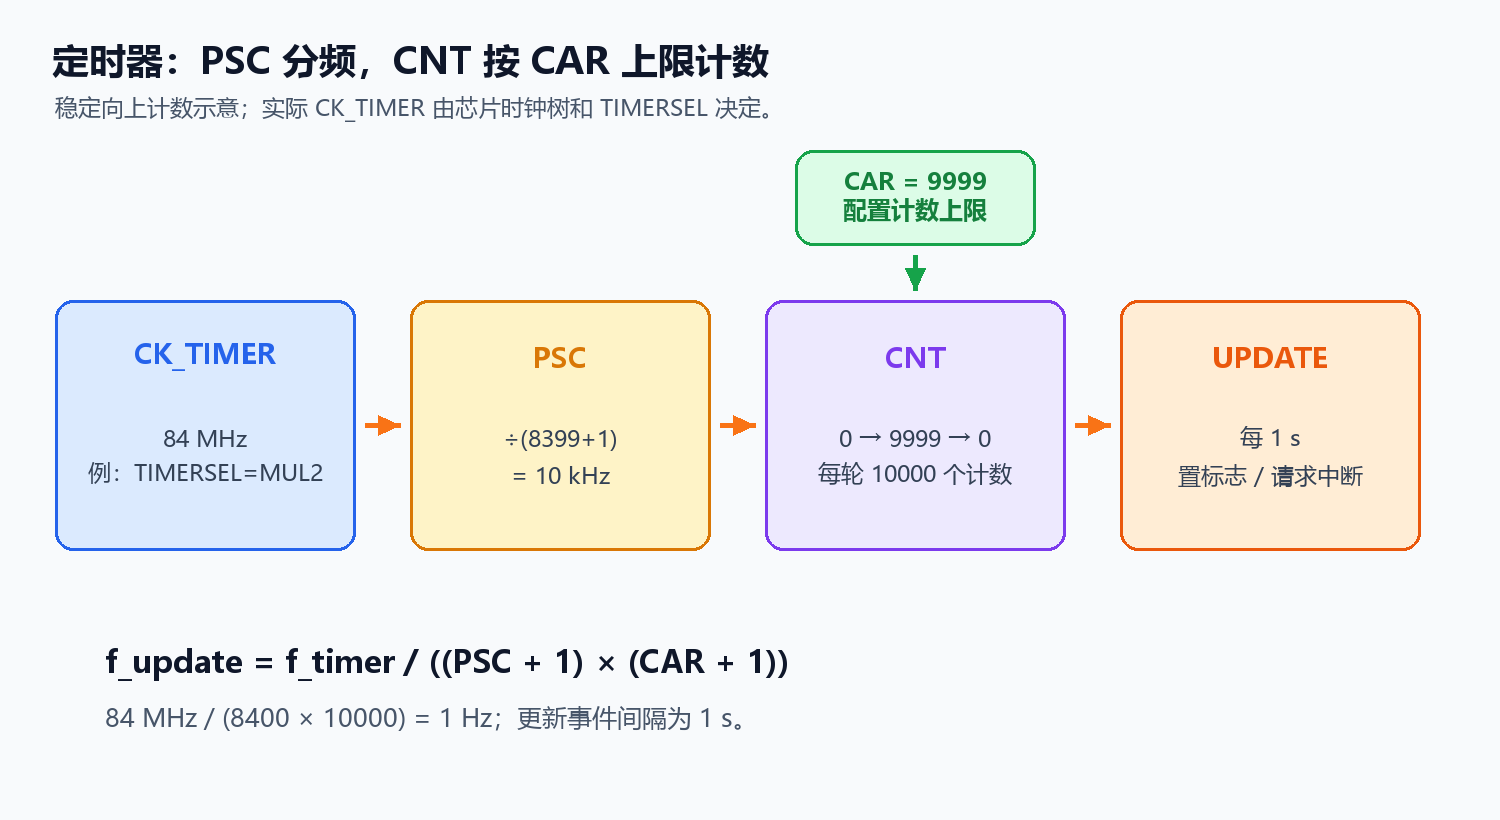

`rcu_timer_clock_prescaler_config()` 对应全局定时器时钟选择，不能在各驱动中随意切换，影响范围需统一规划。本篇独立实验一次性使用 MUL2，不把“2 倍/4 倍”机械套用到所有 APB 分频。

每一级都要有证据：实际 HXTAL、系统配置、APB 分频、TIMERSEL、PSC 和 CAR。手册 3.4 覆盖多个 GD32F4xx 型号，时钟树总图中的上限不能直接当作 F407 的运行目标；本篇沿用课程的 168 MHz 条件，不修改 PLL 或最高频率设置。


## 15. 预分频 PSC 与自动重装 CAR

基本定时器的核心是一个向上计数器。手册定义：

- `PSC` 寄存器值为 `p` 时，计数时钟除以 **p + 1**。
- `CAR` 为 `c` 时，计数器从 0 向上计数到自动重装值，产生更新事件并回到 0；一个完整间隔通常包含 **c + 1 个计数时钟**。

因此，忽略同步和 ISR 开销，更新频率为：

```text
f_update = f_timer / ((PSC + 1) × (CAR + 1))
T_update = ((PSC + 1) × (CAR + 1)) / f_timer
```

### 1 秒更新算例

假设通过时钟树和配置确认 `f_timer = 168 MHz`，想每秒一次更新：

```text
目标计数总数 = 168000000
PSC + 1 = 10000
CAR + 1 = 16800
PSC = 9999
CAR = 16799
```

两者都在 16 位范围内。若实际 `f_timer = 84 MHz`，同一组参数得到 **2 秒周期**，频率减半；反过来，按 84 MHz 设计的参数用于实际 168 MHz 时才会快一倍。

PSC 与 CAR 的寄存器范围各为 0～65535，实际分频因子为 1～65536，计数数量为 CAR+1。以 1 MHz 计数时钟为例，16 位计数器单个周期最大 65.536 ms；想要 1 秒，可增大 PSC、累计软件节拍或选更宽计数资源。

课程短配置写 `prescaler=10000`、`period=16800-1`；按 PSC 字段为寄存器值解释，在 168 MHz 下周期是 1.0001 秒。想要理想 1 秒应写 9999。后续代码采用 84 MHz、PSC=8399、CAR=9999 的另一组精确整数参数。

预分频器有影子寄存器，写入值需要更新事件才能装载。初始化函数可能产生软件更新；使用与自己库版本匹配的更新 API，确认参数装载后清初始化造成的标志，再开放 IRQ。公式描述稳定运行后的间隔，不保证第一次 ISR 的时刻或延迟。


## 16. TIMER5 基本定时器初始化

课程页面给出的流程是：开启时钟、复位、选择定时器倍频、初始化结构体、设置 PSC/CAR、打开更新中断、配置 NVIC、启动定时器。下面把寄存器的加一关系写得明确：

```c
#include "gd32f4xx.h"
#include <stdint.h>

static volatile uint32_t timer5_ticks;

static void timer5_init_1s(void)
{
    NVIC_DisableIRQ(TIMER5_DAC_IRQn);
    rcu_periph_clock_enable(RCU_TIMER5);
    timer_deinit(TIMER5);

    // 独立实验，系统已确认 CK_AHB=168MHz、APB1=/4
    // 全局 TIMERSEL 在应用初始化统一选择 MUL2，得到 CK_TIMER5=84MHz

    timer_parameter_struct tps;
    timer_struct_para_init(&tps);
    tps.prescaler = 8399U;  // 84MHz / 8400 = 10kHz
    tps.period = 9999U;     // 10000 个计数 = 1 秒
    timer_init(TIMER5, &tps);
    timer_event_software_generate(TIMER5, TIMER_EVENT_SRC_UPG);

    timer_interrupt_flag_clear(TIMER5, TIMER_INT_FLAG_UP);
    NVIC_ClearPendingIRQ(TIMER5_DAC_IRQn);
    timer_interrupt_enable(TIMER5, TIMER_INT_UP);
    nvic_irq_enable(TIMER5_DAC_IRQn, 2U, 2U);
    timer_enable(TIMER5);
}

void TIMER5_DAC_IRQHandler(void)
{
    if (SET == timer_interrupt_flag_get(TIMER5, TIMER_INT_FLAG_UP)) {
        timer_interrupt_flag_clear(TIMER5, TIMER_INT_FLAG_UP);
        ++timer5_ticks;
    }
}
```

这是函数定义片段，要求应用先统一执行 `nvic_priority_group_set(NVIC_PRIGROUP_PRE2_SUB2)` 和 `rcu_timer_clock_prescaler_config(RCU_TIMER_PSC_MUL2)`。在独立实验开始前配置，不能在已有多个模块运行时随意改变全局时钟。`timer5_ticks` 只有本 ISR 写，主循环只读。

课程工程需要把 `gd32f4xx_timer.c` 加入 Firmware 分组，与 GPIO/RCU/MISC 等匹配。`timer_event_software_generate(..., TIMER_EVENT_SRC_UPG)` 是本例追加的 SPL 更新调用，用于装载预分频并建立初始计数，再清初始化标志。使用前核对当前库的声明与语义；该 SDK 未在本环境构建。共享 IRQ 的其他来源（DAC）在本独立实验中未使能，真实多模块工程需要分别检查处理。

`timer5_ticks` 的递增只证明更新事件到达 ISR，不证明真实周期已经是 1 秒。测试时应用 GPIO 翻转、逻辑分析仪或另一个可靠时间基准测量。


## 17. 用定时器节拍驱动 LED，而不是在 ISR 里延时

ISR 只更新节拍，LED 控制放在主循环：

```c
int main(void)
{
    core_led_init();
    nvic_priority_group_set(NVIC_PRIGROUP_PRE2_SUB2);
    rcu_timer_clock_prescaler_config(RCU_TIMER_PSC_MUL2);
    timer5_init_1s();

    uint32_t last = 0U;
    bool led_on = false;
    while (1) {
        uint32_t now = timer5_ticks;
        uint32_t elapsed = now - last;
        if (elapsed != 0U) {
            last = now;
            if ((elapsed & 1U) != 0U) {
                led_on = !led_on;
            }
            core_led_write(led_on);
        }
        // 其他非阻塞工作
    }
}
```

本调用片段与第 16 节共用唯一的 timer5_ticks 定义和 Handler，并包含 `<stdbool.h>`；核心灯函数来自第 04 篇。若主循环迟到两拍，奇偶规则直接恢复预期亮灭状态，无法补回错过的真实闪烁；需要逐次输出的应用必须设计截止时间与积压策略。

每 1 秒翻转一次，亮 1 秒、灭 1 秒，LED 的完整周期为 **2 秒、0.5 Hz**；更新事件频率是 1 Hz，二者不同。主循环执行带来的延迟也会让 GPIO 边沿不完全等同于硬件更新时刻。

无符号差值可跨一次 32 位回绕，前提是两次处理间没有累计整整 2^32 个 tick；每 1 ms 计数约 49.71 天回绕，采用它计算时间时必须检查这个条件。


## 18. 定时器更新事件的排查顺序

定时器不进中断时按层次排查：

1. `RCU_TIMER5` 是否开启，Firmware 分组是否含 `gd32f4xx_timer.c`。
2. `timer_deinit()` 和结构体初始化是否执行。
3. `f_timer` 是否由真实晶振、PLL、APB 分频和 TIMERSEL 推导。
4. `PSC`、`CAR` 是否在目标定时器位宽内，是否误把除数写成寄存器值。
5. 更新中断源 `TIMER_INT_UP` 是否打开。
6. NVIC IRQ 名称、优先级和使能是否对应当前型号。
7. 启动文件是否把 `TIMER5_DAC_IRQHandler` 放进向量表。
8. ISR 是否清除正确的 `TIMER_INT_FLAG_UP`。
9. 是否在调试暂停时配置了 TIMER hold，导致计数器停止。

若 ISR 一直重复进入，优先检查标志是否清除；若 LED 频率稳定但快/慢固定倍数，优先检查 TIMERSEL、APB 分频和 `(PSC+1)/(CAR+1)`。


## 19. PWM：定时器把时间比例变成波形

PWM 不是“模拟输出”。它用数字高低电平快速切换，通过周期和高电平时间的比例表达平均功率或控制量：

```text
频率 f_pwm = f_counter / (CAR + 1)
占空比 D ≈ compare / (CAR + 1)
```

下面针对连续向上计数、边沿对齐、PWM0、有效高输出，并把比较值记为 GD32 的 `CHxCV`。若 CNT < CHxCV 时输出有效，上式可直接用于高电平比例；换用其他 PWM 模式或输出极性时，比较关系和占空比方向要按手册重新确认。

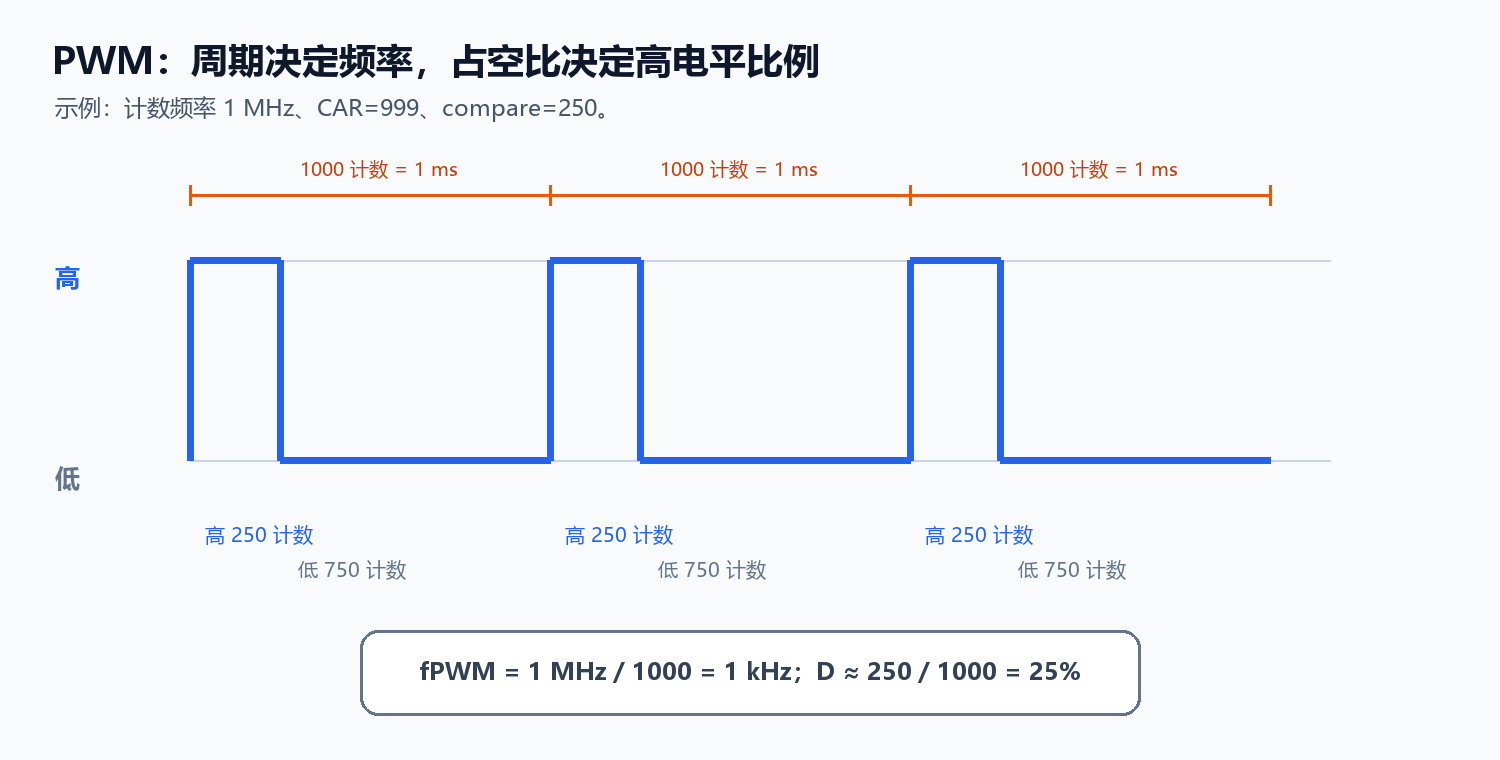

### 1 kHz、25% 占空比算例

假设确认某个 PWM 定时器的 `f_timer = 84 MHz`，选择 `PSC = 83`，得到 1 MHz 计数频率；选择 `CAR = 999`，则周期为 1000 个计数，即 1 kHz。若比较值按“高电平计数数目”解释，`compare = 250` 约为 25%。

```text
f_counter = 84 MHz / (83 + 1) = 1 MHz
f_pwm = 1 MHz / (999 + 1) = 1 kHz
D ≈ 250 / 1000 = 25%
```

这个例子没有指定具体通道和引脚；真实配置还要设置 GPIO 复用、输出极性、预装载和通道比较寄存器。`PB9` 在第 04 篇作为蜂鸣器 GPIO，若改为定时器复用输出，必须重新核对 AF 表和板级驱动电路。


## 20. 捕获、比较与输入测量的入口

常规定时器的其他功能可以用同一套“计数时间轴”理解：

| 功能 | 定时器做什么 | 常见用途 |
|---|---|---|
| 输出比较 | CNT 与比较值相等时产生事件/改变输出 | 精准翻转、单脉冲 |
| 输入捕获 | 在输入边沿把 CNT 锁存到捕获寄存器 | 测频率、测脉宽 |
| PWM 输入/捕获 | 分别捕获周期和高电平时间 | 占空比与频率测量 |
| 外部计数 | 用输入事件推动计数 | 编码器、脉冲计数 |

课程定时器组的超声波案例用 GPIO 触发 HC-SR04，并测量 ECHO 高电平持续时间；第 04 篇没有展开此案例。课程页面标题写 HR-SC04，附件和器件说明为 HC-SR04，本篇按后者理解。

课程映射 TRIG→PC6、ECHO→PC7、模块供电 5 V。PC6 与第 04 篇的八灯总开关冲突，不能把两个实验直接合并；应拆分实验或根据原理图重新分配引脚。5 V 模块的 ECHO 输出接到 MCU 前，需要核对该具体脚在当前模式的输入电压容限；不能假定所有 3.3 V GPIO 都耐受 5 V，不满足时使用合适电平转换。

触发提供至少 10 µs 的高脉冲，ECHO 高电平宽度代表往返时间。以声速 340 m/s 为计算假设：

```text
distance_cm = echo_us × 340 × 100 / (2 × 1000000)
            = echo_us × 0.017
```

ECHO=1000 µs 对应约 17 cm；课程的“µs/58”是另一种常用近似，隐含声速约 345 m/s，不能称为与 340 m/s 完全一致。温度、目标表面和模块状态都会影响测量，不把标称毫米精度当作实际实验结果。

轮询测量容易被其他工作打断；输入捕获可以在边沿发生时硬件锁存时间，再由 ISR 或 DMA 读取。若定时计数为 1 MHz，16 位计数器 65.536 ms 回绕，4 m 的理想往返时间约 23.53 ms。只跨一次回绕且间隔小于容量时，可按模差计算脉宽：

```c
uint32_t width = (fall_capture - rise_capture) & 0xFFFFU;
```

这是假设 CAR=65535 的 16 位计数片段；若 CAR 取其他值，模数是 CAR+1，不能继续硬套 0xFFFF。实际捕获还要配置输入通道/边沿/滤波、读取捕获标志，并处理捕获溢出。等待上升沿、等待下降沿都需要超时和错误结果，避免传感器无响应时永久卡住。

不要用 `delay_1us()` 反复忙等来替代所有测量。先确认输入电平容限、电源电压、触发宽度和传感器时序，再选择 GPIO 轮询、定时器输入捕获或更高层的驱动。


## 21. 完整 main.c：1 ms TIMER5 节拍与按键消抖

这个完整应用源文件把第 04 篇连续样本确认改成非阻塞采样。**TIMER5 ISR 每 1 ms 只计数；主循环约每 5 ms 读 PA0，连续 5 次确认，按下事件翻转 PB2。**不启用按键 EXTI，便于先验证定时器中断与消抖；第 07～09 节的 EXTI 是其他独立实验。

前提：匹配的 F407 启动/system/SPL，系统已确认 CK_AHB=168 MHz、APB1=/4；全局 MUL2 得到 TIMER5 输入 84 MHz。`gd32f4xx_timer.c`、RCU/GPIO/MISC 等实现已加入工程。模板已有 TIMER5_DAC_IRQHandler 时改原函数，确保只有一份；此源文件与第 16 节的 1 秒示例分别运行。

```c
#include "gd32f4xx.h"
#include <stdbool.h>
#include <stdint.h>

static volatile uint32_t tick_ms;

typedef struct {
    bool candidate;
    bool stable;
    uint8_t count;
} KeyFilter;

static bool key_step(KeyFilter *key, bool raw_pressed)
{
    if (raw_pressed != key->candidate) {
        key->candidate = raw_pressed;
        key->count = 1U;
    } else if (key->count < 5U) {
        ++key->count;
    }
    if (key->count == 5U && key->stable != key->candidate) {
        key->stable = key->candidate;
        return key->stable;
    }
    return false;
}

static void board_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOA);
    rcu_periph_clock_enable(RCU_GPIOB);
    gpio_mode_set(GPIOA, GPIO_MODE_INPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_0);
    gpio_bit_reset(GPIOB, GPIO_PIN_2);
    gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_2);
    gpio_output_options_set(GPIOB, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, GPIO_PIN_2);
}

static void core_led_write(bool on)
{
    if (on) {
        gpio_bit_set(GPIOB, GPIO_PIN_2);
    } else {
        gpio_bit_reset(GPIOB, GPIO_PIN_2);
    }
}

static void timer5_tick_init(void)
{
    NVIC_DisableIRQ(TIMER5_DAC_IRQn);
    rcu_periph_clock_enable(RCU_TIMER5);
    timer_deinit(TIMER5);

    timer_parameter_struct tps;
    timer_struct_para_init(&tps);
    tps.prescaler = 83U;    // 84MHz / 84 = 1MHz
    tps.period = 999U;      // 1000us = 1ms
    timer_init(TIMER5, &tps);
    timer_event_software_generate(TIMER5, TIMER_EVENT_SRC_UPG);
    timer_interrupt_flag_clear(TIMER5, TIMER_INT_FLAG_UP);
    NVIC_ClearPendingIRQ(TIMER5_DAC_IRQn);
    timer_interrupt_enable(TIMER5, TIMER_INT_UP);
    nvic_irq_enable(TIMER5_DAC_IRQn, 2U, 2U);
    timer_enable(TIMER5);
}

void TIMER5_DAC_IRQHandler(void)
{
    if (SET == timer_interrupt_flag_get(TIMER5, TIMER_INT_FLAG_UP)) {
        timer_interrupt_flag_clear(TIMER5, TIMER_INT_FLAG_UP);
        ++tick_ms;
    }
}

int main(void)
{
    KeyFilter key = {0};
    bool led_on = false;
    uint32_t last_sample = 0U;

    board_init();
    nvic_priority_group_set(NVIC_PRIGROUP_PRE2_SUB2);
    rcu_timer_clock_prescaler_config(RCU_TIMER_PSC_MUL2);
    timer5_tick_init();

    while (1) {
        uint32_t now = tick_ms;
        if ((uint32_t)(now - last_sample) >= 5U) {
            last_sample = now;
            bool raw = (gpio_input_bit_get(GPIOA, GPIO_PIN_0) == SET);
            if (key_step(&key, raw)) {
                led_on = !led_on;
            }
            core_led_write(led_on);
        }
        // 其他短的非阻塞任务；不要在这里播放整曲或长延时
    }
}
```

预期：稳定按下后灯翻转一次，长按保持，释放确认后再次按下才再翻转。函数返回 false 只表示没有新按下事件，当前状态在 key.stable。初始稳定状态设为松开，上电时已按住也会在确认后产生一次事件。

5 个样本首末跨 4 个间隔，理想跨度 20 ms，实际从物理边沿到识别还包含采样相位和调度延迟。主循环迟到时只取一个真实样本，**不循环补做多个相同样本**；那样会把一次读数伪装成五次观察。此写法保证约定的最小间隔，无法承诺严格等距；迟到会延长响应。

连续屏蔽 TIMER5 中断超过 1 ms 时，挂起位可能合并多次溢出，tick_ms 漏计；应保持 ISR/临界区短，并测量最坏延迟。本例没有调用 systick_config/delay_1ms，已有 SysTick 用户仍按原配置管理，不能重复定义 Handler。

若系统需要 EXTI 唤醒按键确认，可以用“边沿提示 → 启动周期采样 → 稳定按下产生事件 → 稳定释放结束”的状态机。单次延时后读一次、只检测按下却不确认释放，都不能替代这个完整状态过程；低功耗设计在第 07 篇进一步展开。


## 22. 时基设计：让扫描、发声和业务互不阻塞

把三个周期任务放到不同层：

```text
1 ms 定时节拍 → 更新按键采样与软件计时
PWM 定时器    → 持续产生蜂鸣器/电机波形
主循环        → 消费按键事件，更新 LED、歌曲和显示
```

第 04 篇的阻塞式 `tone_burst()` 在发声期间无法保证固定采样间隔；改用 PWM 后，CPU 不必每个半周期手动置位 PB9。第 05 篇的定时器让“时间”从业务循环中分离出来。

| 任务 | 周期 | 执行位置 |
|---|---:|---|
| 按键原始采样 | 5 ms | 主循环，由 SysTick/TIMER 节拍定时 |
| LED 状态刷新 | 5～20 ms | 主循环消费事件 |
| 音频 PWM | 由音符决定 | 定时器通道硬件输出 |
| 通信收发 | 事件驱动 | USART ISR/DMA，详见第 06 篇 |
| 超声波测量 | 触发与捕获边沿 | GPIO + 定时器捕获 |


## 23. 软件触发、pending 与清标志

EXTI 支持软件触发：开启中断后设置软件触发寄存器，硬件可以像边沿触发一样产生请求。它适合测试向量入口或唤醒路径，但不代表 GPIO 电平真的发生了变化。

NVIC 还可以设置和清除 device-specific pending 状态。pending 只表示请求等待处理，active 表示处理器已经进入 ISR。清 NVIC pending 不能代替清外设/EXTI 的源标志；否则源头仍会再次请求。

对“写 1 清除”的寄存器必须按手册语义操作。GD32F4xx EXTI pending 寄存器的相关位是写 1 清除；不能用普通读改写方式想当然地写 0。定时器不同标志也可能有各自的清除规则，以 SPL 函数或寄存器章节为准。


## 24. 常见错误与排查顺序

| 现象 | 可能原因 | 先检查 |
|---|---|---|
| EXTI 不触发 | 没开 SYSCFG、映射错线、NVIC 未使能 | GPIO/EXTI/SYSCFG/NVIC 四层 |
| 按一次触发多次 | 机械抖动或双边沿误配 | 电平、触发沿、消抖 |
| 进入 ISR 后出不来 | 忘记清源标志，或标志持续为 1 | EXTI/TIMER flag clear |
| TIMER5 ISR 名字无效 | IRQ 入口与芯片启动文件不符 | 设备头文件和向量表 |
| 定时快两倍 | APB/TIMERSEL/库倍频误判 | 实际 `f_timer` |
| 定时慢一倍 | PSC/CAR 或加一关系写错 | `(PSC+1)*(CAR+1)` |
| 1 ms 延时卡死 | SysTick 配置、Handler 或共享变量链路断开 | `SysTick_Handler` |
| PWM 频率对，波形不对 | AF、极性、compare 语义错误 | 引脚表和通道配置 |
| 按键 ISR 影响歌曲 | ISR 内播放或打印 | 把业务移到主循环 |
| 变量偶尔错 | 共享数据竞态或 flag 丢事件 | volatile、临界区、队列 |

排查顺序：

```text
实际时钟/引脚 → 外设时钟 → 源配置 → 外设中断位
→ NVIC/向量表 → ISR 标志 → 共享变量 → 业务处理
```


## 25. 实验验收与动手练习

| 实验 | 验收标准 |
|---|---|
| EXTI 按键 | PA0 上升沿或 PC0 下降沿与电路极性一致，ISR 能清标志 |
| 事件投递 | ISR 只写 flag/计数，主循环完成 LED 动作 |
| 切歌 | 按键能修改播放状态，当前音符边界可退出，ISR 不阻塞 |
| SysTick | 1 ms 节拍链路完整，延时单位和时钟源相符 |
| TIMER5 | PSC/CAR 计算可复核，更新 ISR 稳定进入 |
| PWM | 实测频率与占空比符合目标，AF 和极性正确 |

### 自测

1. 只使能 NVIC 而不使能外设中断位，为什么可能不进 ISR？
2. PA0 外部下拉按下为高，PC0 内部上拉按下为低，分别选择什么触发沿？
3. 为什么 EXTI0 不能同时接收 PA0 与 PC0 两个独立来源？
4. `volatile` 能否保证一个多字段结构体更新不会被主循环读到半成品？
5. 抢占优先级与子优先级分别解决什么问题？
6. `PSC=9999`、`CAR=16799`，实际总分频乘数是多少？
7. `f_timer=168 MHz` 时，这组参数的更新周期是多少？
8. 为什么不能把 `GPIO_OSPEED_2MHZ` 当作 PWM 频率？
9. TIMER5 为什么不能直接输出某个 GPIO 上的 PWM？
10. ISR 反复进入时，为什么只清 NVIC pending 可能不够？

### 动手练习

1. 把第 04 篇 PA0 按键改为 EXTI 上升沿，ISR 只设置事件标志；主循环复用消抖状态。
2. 用 TIMER5 每 10 ms 产生更新事件，实现不阻塞的按键采样节拍。
3. 假设 `f_timer=84 MHz`，设计 100 Hz 更新：选择合适 PSC/CAR，并写出计算过程。
4. 假设计数频率 1 MHz，设计 20 kHz、50% PWM，写出 CAR 与 compare 的假设。
5. 用逻辑分析仪比较第 04 篇软件方波和 PWM 输出的周期抖动。


## 26. 参考答案与关键算例

| 题号 | 参考答案 |
|---|---|
| 1 | 外设源、NVIC 通道和全局条件分别控制不同层；只开 NVIC 不等于源已允许 |
| 2 | PA0 选上升沿，PC0 选下降沿；还要匹配上下拉和实际板线 |
| 3 | 同一 EXTI 线号只能选一个 GPIO 端口来源 |
| 4 | 不能；volatile 不提供复合更新的互斥或原子性 |
| 5 | 抢占决定能否打断当前 ISR；子优先级决定同抢占级 pending 的先后 |
| 6 | `10000 × 16800 = 168,000,000` 个计数时钟 |
| 7 | 1 秒，前提是 `f_timer=168 MHz` 且定时器确实使用该时钟 |
| 8 | 它是 GPIO 输出边沿速度档位，PWM 频率由定时器时间轴决定 |
| 9 | 基本定时器没有捕获/比较通道和 GPIO 复用输出 |
| 10 | 源标志仍为 1，会再次把 NVIC pending 置起 |

### 另一个算例

`f_timer=84 MHz`，目标更新频率 100 Hz，选 `PSC=8399`，则计数频率为 10 kHz；选 `CAR=99`，更新频率为 `10000/(99+1)=100 Hz`。

`f_counter=1 MHz`，目标 20 kHz，周期计数为 50；`CAR=49`。50% 占空比若按比较值代表高电平计数数目，`compare=25`，但要以具体通道极性和库函数定义实测确认。


## 27. 一页复习与十二篇路线

| 主题 | 记住这条规则 |
|---|---|
| 中断链路 | 源事件 → 源标志 → 外设允许 → NVIC → 向量 → ISR |
| ISR | 快速确认、清标志、投递事件；长业务放主循环 |
| EXTI | GPIO 来源先映射到线号，再选择上升/下降/双边沿 |
| NVIC | 抢占和子优先级按配置工作，不会自动老化 |
| SysTick | 内核 24 位定时器，依赖正确时钟源与 Handler |
| 基本定时器 | TIMER5/6 无通道，适合更新事件和周期节拍 |
| 定时计算 | `f_update=f_timer/((PSC+1)(CAR+1))` |
| PWM | 周期决定频率，比较值决定占空比，AF 决定输出脚 |
| 测量 | 计算值和真实波形之间要用仪器验证 |

| 编号 | 笔记主题 |
|---|---|
| 01 | C语言核心语法与函数 |
| 02 | C语言指针与内存 |
| 03 | 单片机入门与开发环境 |
| 04 | GPIO与基础外设控制 |
| **05** | **中断与定时器（本篇）** |
| 06 | 串口、DMA与通信模块 |
| 07 | 实时时钟与系统管理 |
| 08 | I2C与SPI通信 |
| 09 | ADC与传感器采集 |
| 10 | 存储器与文件系统 |
| 11 | 屏幕显示与触摸驱动 |
| 12 | LVGL图形界面开发 |

下一篇将把本篇的事件标志和定时节拍接到串口接收、DMA 缓冲区与通信协议。


## 28. 课程来源索引与核对范围

核对日期：2026-10-11～12。

| 分组 | 课程页面 |
|---|---|
| 中断 | [中断基础概念](https://www.yuque.com/xxcls/mcu/ye0cwn822365i16l)、[外部中断 EXTI](https://www.yuque.com/xxcls/mcu/yh2d03ad9a7l5tph)、[按键切换音乐播放器](https://www.yuque.com/xxcls/mcu/tntqnypxupakn2r1) |
| 定时器 | [GD32F4 定时器查询](https://www.yuque.com/xxcls/mcu/qz4k12gpgsansdt3)、[时钟周期](https://www.yuque.com/xxcls/mcu/znqfc8r5082cclnb)、[定时器概述](https://www.yuque.com/xxcls/mcu/xudaif81texdyd7y)、[SysTick 内核定时器](https://www.yuque.com/xxcls/mcu/oliscew0zgsny45l)、[分频器](https://www.yuque.com/xxcls/mcu/ovrscaioix1msaui)、[晶振、锁相环、总线时钟](https://www.yuque.com/xxcls/mcu/xx4kikeq7uslh311)、[基本定时器](https://www.yuque.com/xxcls/mcu/ye981olkie6gb9q2) |
| 延伸案例 | [HC-SR04 超声波传感器](https://www.yuque.com/xxcls/mcu/ewr1m8rf9nei4z9s) |
| 官方参考 | [CMSIS NVIC](https://arm-software.github.io/CMSIS_6/main/Core/group__NVIC__gr.html)、[CMSIS SysTick](https://arm-software.github.io/CMSIS_6/main/Core/group__SysTick__gr.html)、[GD32F4xx User Manual](https://gd32mcu.com/download/down/document_id/98/path_type/1) |

官方手册采用 **GD32F4xx User Manual 3.4**，已保存[本地副本](C:/Users/23224/Desktop/stack-blueprint/work/mcu-note05-source/GD32F4xx_User_Manual.pdf)。以下页码按 PDF 页序（从 1 开始）记录，便于直接定位：

| 核对内容 | PDF 页码 |
|---|---|
| IRQ 向量、NVIC 优先级位 | 93～94 |
| 时钟树、TIMERSEL 与 APB 倍频规则 | 144 |
| EXTI 线路、GPIO 来源映射、挂起标志 | 161、163～166、170 |
| 通用 L0 定时器、TIMER1/4 与 TIMER2/3 的位宽 | 421～422、433、435 |
| TIMER5/6 基本定时器、PSC 与 CAR | 507～509、515～516 |

本次重点核对了时钟树与 TIMERSEL、EXTI 的 23 条边沿检测与 GPIO 线映射、NVIC 4 位优先级、TIMER5/6 的 16 位计数器、PSC 为 `PSC+1` 分频以及 CAR 的自动重装语义；144、421、516 页另核对了页面图表。没有把手册全部章节抄入笔记。

本篇代码示例、公式配图和练习是学习补充；`code_examples_compiled=false`、`hardware_run=false`，真实实验请以自己的芯片手册、启动文件、SPL 版本、原理图和仪器测量结果为准。
